In [3]:
from scr import mutation_estimation

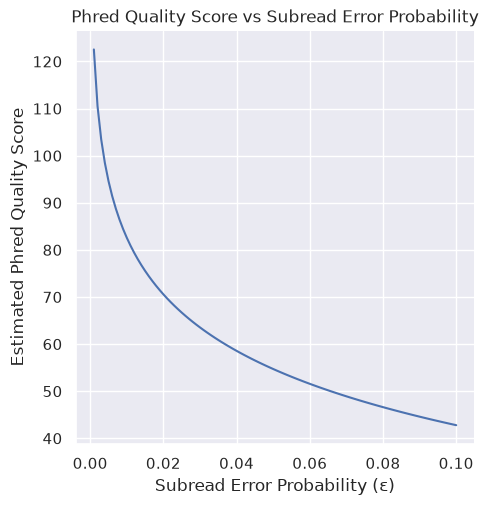

In [4]:
mutation_estimation.plot_phred_eps_dependency(0.001, 0.1, 100, 6)

### Cosmic Mutations

In [5]:
import pandas as pd

In [6]:
mutations = pd.read_csv("data/thyroid/nanoseq_mutation_data.tsv", sep="\t")
genome_tri_prop_path = "data/h19_tri32.csv"
seq_path = "data/thyroid/tnfrsf14.fasta"

Length of target sequence: 9744


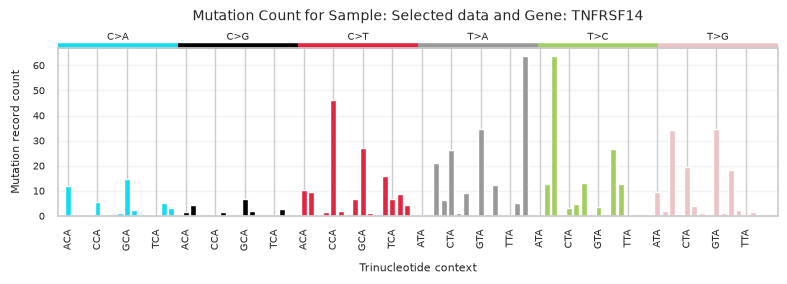

In [7]:
from scr.sbs96_computation import (
    add_sample_metadata,
    build_sbs96_matrix,
    select_mutations,
    tri_correct,
    plot_sbs96_matrix
)

mutations = add_sample_metadata(mutations)

selected = select_mutations(
    mutations,
    # donor_biopsy_id="PD63118b",
    gene="TNFRSF14",
)

matrix = build_sbs96_matrix(selected)
corr_matrix = tri_correct(mut_matrix=matrix, 
                          genome_tri_prop_path=genome_tri_prop_path,
                          seq_path=seq_path)

sbs96_matrix_ax = plot_sbs96_matrix(corr_matrix, save_image=False)

### Test of EM algorithm

In [8]:
from scr.signature_estimation import em_algorithm, em_visualization, signatures_visualization

In [9]:
cosmic_path = "data/COSMIC_v3.5_SBS_GRCh37.txt"

In [10]:
new_signature_prop, q_function_values, expected_counts_per_signature, normalized_mutation_df = em_algorithm(corr_matrix, cosmic_path, signature_prop=None, max_iter=100, tol=1e-5)

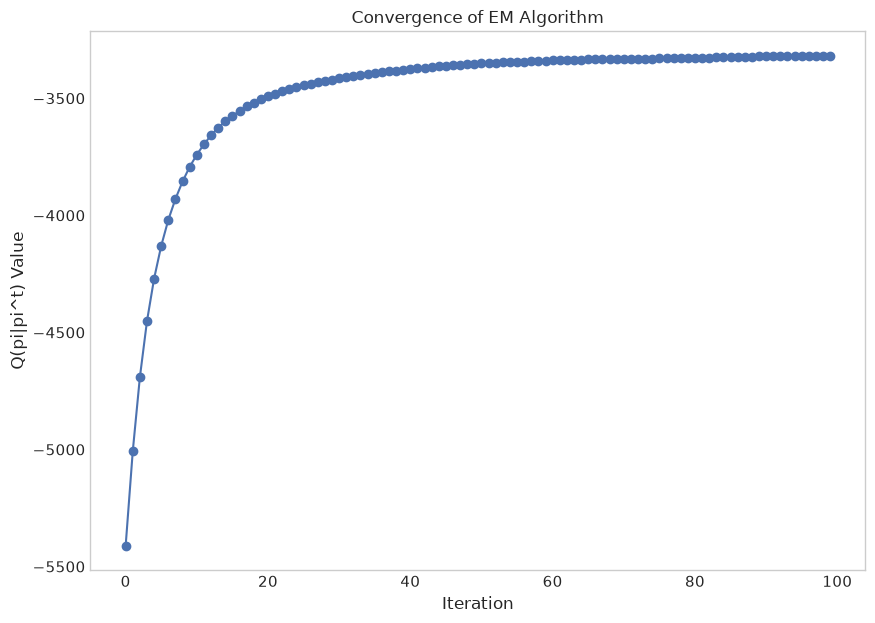

In [11]:
em_visualization(q_function_values)

### Singature composition visualization

In [12]:
totals = expected_counts_per_signature.sum(axis=0)
top_sbs = totals.nlargest(5).index

expected_counts_top_sbs = expected_counts_per_signature.loc[:, top_sbs]

/home/bee/code/mutrate/scr/signature_estimation.py:243: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


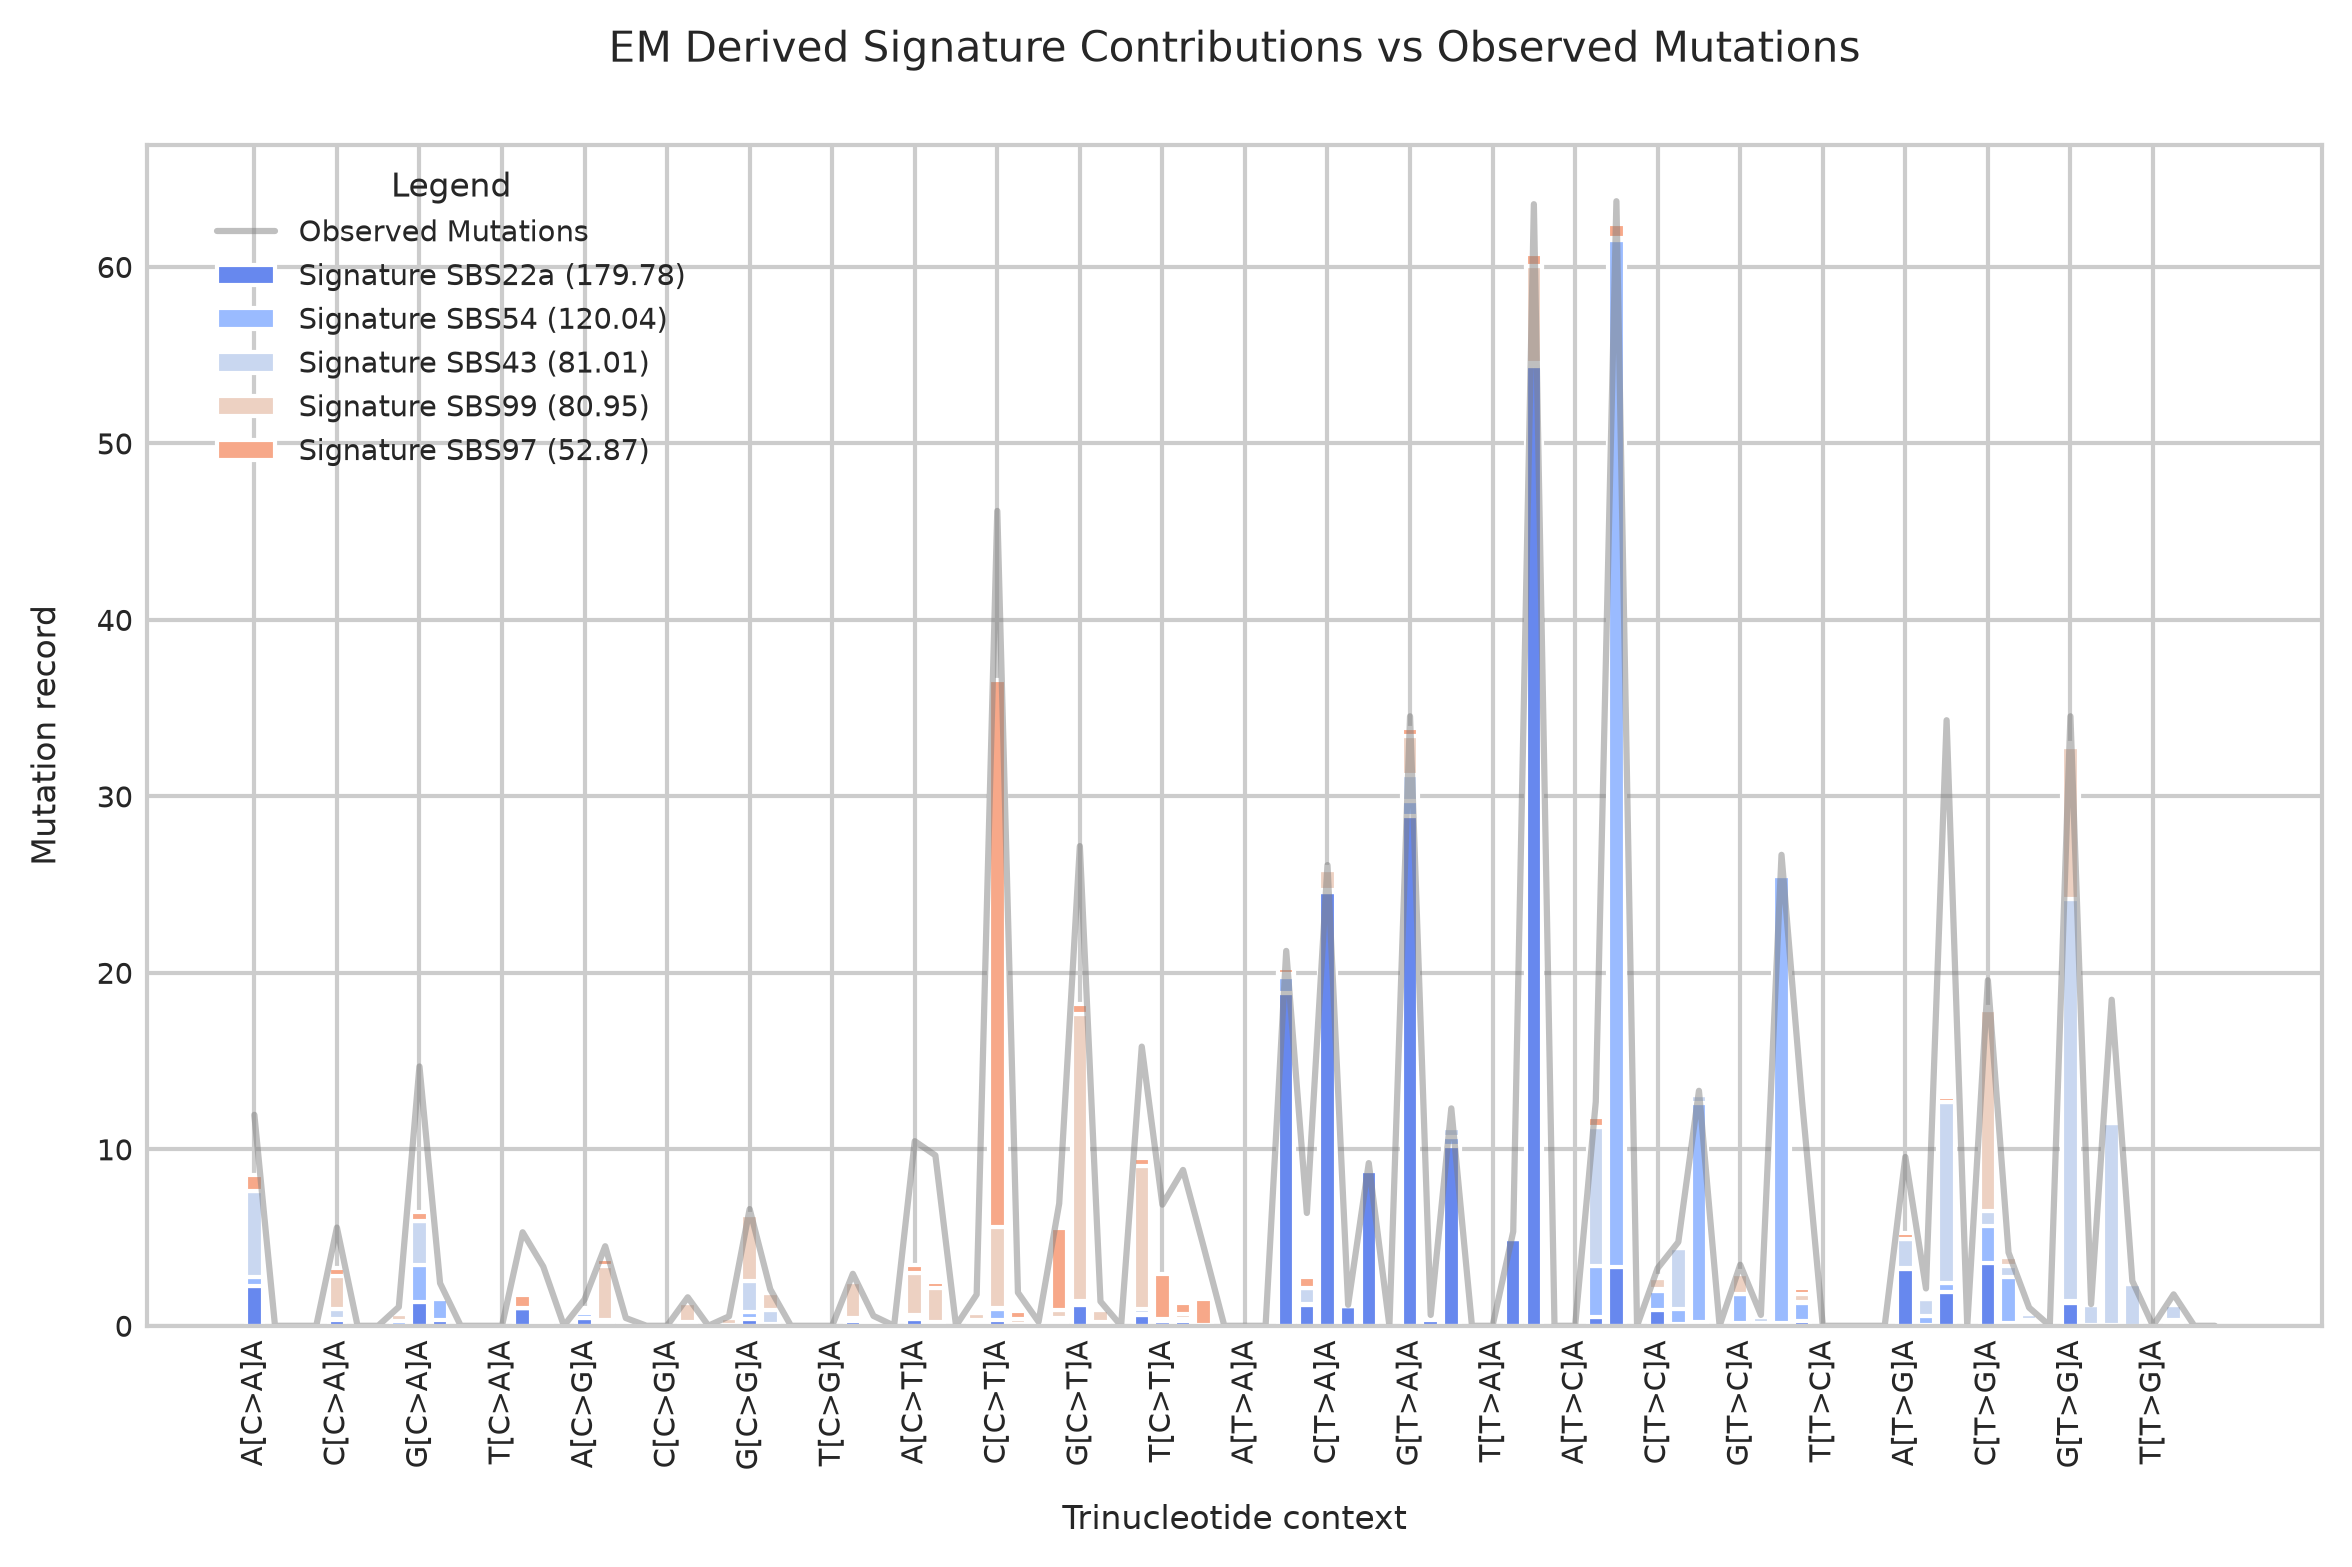

In [13]:
signatures_visualization(expected_counts_per_signature=expected_counts_top_sbs, normalized_matrix=normalized_mutation_df)